<a href="https://colab.research.google.com/github/hjmohamedbilal/movies-dataset/blob/main/MohamedBilalHJExperiment4BTDS332.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 4: Exploratory Data Analysis (EDA) on the Titanic Dataset

1. Import libraries and load the dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Seaborn's example Titanic dataset into a Pandas DataFrame.
df = sns.load_dataset("titanic")

print("Dataset loaded successfully.")
print(f"Number of rows (passengers): {df.shape[0]}")
print(f"Number of columns (variables): {df.shape[1]}")

Dataset loaded successfully.
Number of rows (passengers): 891
Number of columns (variables): 15


2. Preview the dataset

In [2]:
print("First five rows:")
display(df.head())

print("Column names:")
print(df.columns.tolist())

First five rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


3. Understand the dataset structure

In [3]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


4. Generate descriptive statistics

In [4]:
print("Summary statistics for numerical columns:")
display(df.describe())

print("Missing values in each column:")
display(df.isna().sum().sort_values(ascending=False))

Summary statistics for numerical columns:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Missing values in each column:


,0
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


5. Count plot: passenger survival by gender

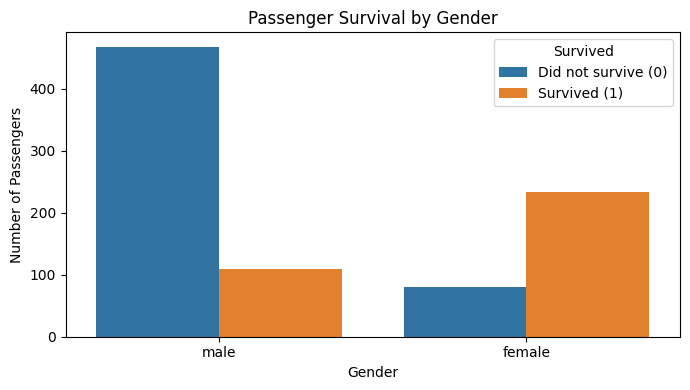

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="sex", hue="survived")

plt.title("Passenger Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["Did not survive (0)", "Survived (1)"])
plt.tight_layout()
plt.show()

Bar plot: survival rate by passenger class

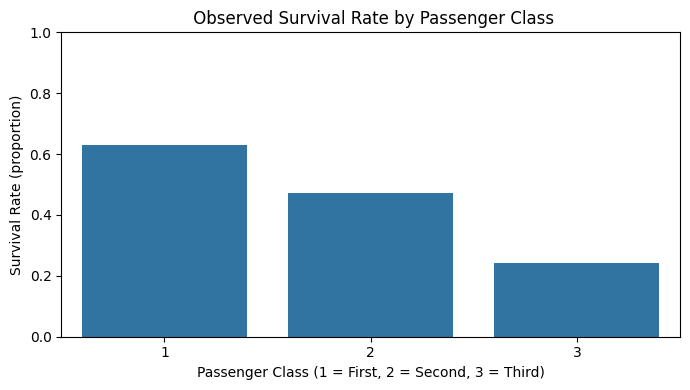

In [6]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="pclass", y="survived", errorbar=None)

plt.title(" Observed Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (proportion)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

7. Correlation heatmap of numerical features

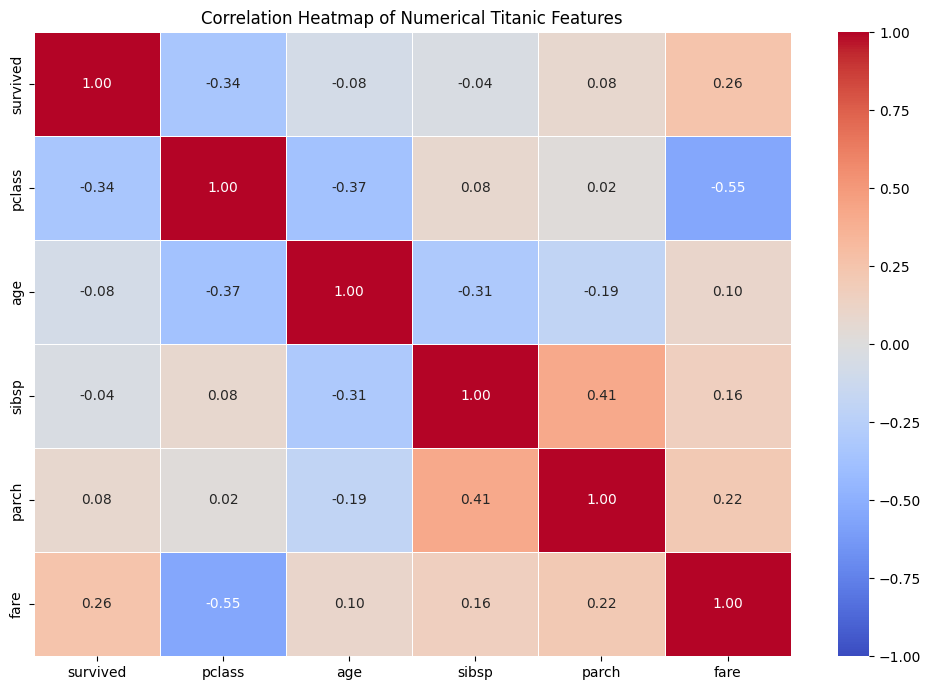

In [7]:
# Keep only numeric columns before calculating correlations.
numeric_df = df.select_dtypes(include=["number"])
# Calculate pairwise correlation coefficients.
correlation = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation Heatmap of Numerical Titanic Features")
plt.tight_layout()
plt.show()